# Sơ đồ ba phương pháp học tổ hợp: Bagging, Boosting, Stacking (mục 9.2.1)

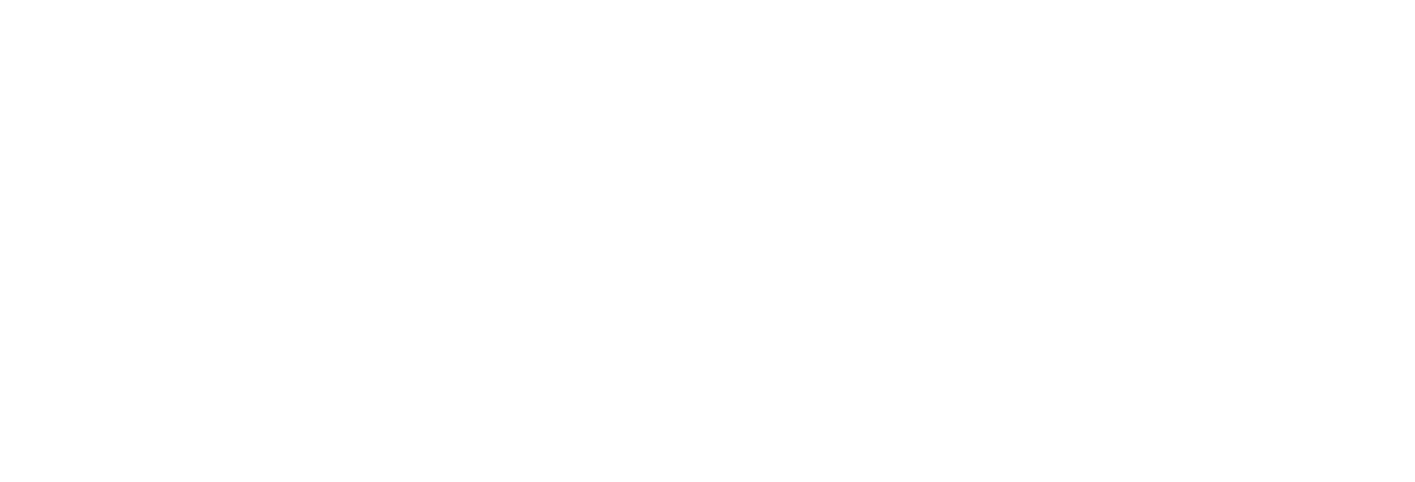

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

def box(ax, x, y, text, color, w=1.7, h=0.75, fontsize=10):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle='round,pad=0.05', fc=color, ec='#444'))
    ax.text(x, y, text, ha='center', va='center', fontsize=fontsize)

def arrow(ax, start, end, text=None):
    ax.annotate('', xy=end, xytext=start, arrowprops=dict(arrowstyle='->', color='#555', lw=1.2))
    if text:
        ax.text((start[0] + end[0]) / 2 + 0.1, (start[1] + end[1]) / 2, text, fontsize=8, color='#555')

DATA, MODEL, RESULT = '#E8EEF7', '#D4EDDA', '#F8D7DA'
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax in axes:
    ax.set_xlim(0, 8); ax.set_ylim(0, 8); ax.axis('off')

(a) Bagging: song song trên các mẫu bootstrap

In [2]:
ax = axes[0]
box(ax, 4, 7.2, 'Tập huấn luyện $D$', DATA, w=3)
for i, x in enumerate([1.3, 4, 6.7]):
    name = '$h_T$' if i == 2 else '$h_%d$' % (i + 1)
    sample = '$D_T$' if i == 2 else '$D_%d$' % (i + 1)
    box(ax, x, 5.3, 'Mẫu bootstrap\n' + sample, DATA)
    box(ax, x, 3.4, 'Mô hình ' + name, MODEL)
    arrow(ax, (4, 6.8), (x, 5.7))
    arrow(ax, (x, 4.9), (x, 3.8))
    arrow(ax, (x, 3.0), (4, 1.9))
ax.text(5.35, 4.3, '…', fontsize=16)
box(ax, 4, 1.5, 'Bỏ phiếu / trung bình', RESULT, w=3)
ax.set_title('(a) Bagging: huấn luyện song song, độc lập\n→ giảm phương sai', fontsize=12)

Text(0.5, 1.0, '(a) Bagging: huấn luyện song song, độc lập\n→ giảm phương sai')

(b) Boosting: tuần tự, tăng trọng số mẫu sai

In [3]:
ax = axes[1]
box(ax, 1.2, 6.8, 'Dữ liệu,\ntrọng số $w^{(1)}$', DATA, w=1.9)
box(ax, 1.2, 4.9, 'Mô hình $h_1$', MODEL, w=1.9)
box(ax, 4.0, 6.8, 'Dữ liệu,\ntrọng số $w^{(2)}$', DATA, w=1.9)
box(ax, 4.0, 4.9, 'Mô hình $h_2$', MODEL, w=1.9)
box(ax, 6.8, 6.8, 'Dữ liệu,\ntrọng số $w^{(T)}$', DATA, w=1.9)
box(ax, 6.8, 4.9, 'Mô hình $h_T$', MODEL, w=1.9)
for x in [1.2, 4.0, 6.8]:
    arrow(ax, (x, 6.4), (x, 5.3))
    arrow(ax, (x, 4.5), (4.0, 2.0))
arrow(ax, (2.15, 4.9), (3.05, 6.5), 'tăng trọng số\nmẫu sai')
arrow(ax, (4.95, 4.9), (5.85, 6.5))
ax.text(5.25, 5.6, '…', fontsize=16)
box(ax, 4.0, 1.6, 'Tổng có trọng số\n$\\mathrm{sgn}(\\sum_t \\alpha_t h_t(\\mathbf{x}))$', RESULT, w=3.4, h=0.95)
ax.set_title('(b) Boosting: huấn luyện tuần tự, mô hình sau sửa lỗi mô hình trước\n→ giảm thiên lệch', fontsize=12)

Text(0.5, 1.0, '(b) Boosting: huấn luyện tuần tự, mô hình sau sửa lỗi mô hình trước\n→ giảm thiên lệch')

(c) Stacking: mô hình meta học cách kết hợp

In [4]:
ax = axes[2]
box(ax, 4, 7.2, 'Tập huấn luyện $D$', DATA, w=3)
for x, name in [(1.3, 'Hồi quy\nLogistic'), (4, 'SVM'), (6.7, 'Cây quyết định')]:
    box(ax, x, 5.3, name, MODEL)
    arrow(ax, (4, 6.8), (x, 5.7))
    arrow(ax, (x, 4.9), (4, 3.75))
box(ax, 4, 3.4, 'Dự đoán của các mô hình cơ sở\n(tạo bằng kiểm định chéo)', DATA, w=4.2, h=0.75)
box(ax, 4, 1.5, 'Mô hình meta\n(ví dụ hồi quy Logistic)', RESULT, w=3.2, h=0.85)
arrow(ax, (4, 3.0), (4, 1.95))
ax.set_title('(c) Stacking: các mô hình khác loại,\nmô hình meta học cách kết hợp', fontsize=12)
fig.tight_layout()
fig.savefig(IMAGES / 'ensemble_methods.png', dpi=150)